# 시장 파워와 미러 분리

**용도** — 글로벌 차트 작품이 같은 주에 국가 차트에도 오르는 비율(동시진입률 — 파나마 미러 발견의 출발점)을 계산하고, 누적 vs 기간별 파워 기준 차이를 검증하며, 파워 상위 8개국·연도별 파워 이동 그림과 NNLS v3 결과 정합성을 확인한다.

**보고서 대응** — 보고서 '나라별 영향력에서의 문제 발견' + 그림 1 · EDA 2 시장 파워와 미러(그림 2·3) · 미러 효과 분리 박스

**환경** — Python 3.15 / pandas 3.1.1 / scikit-learn 1.9.1 / LightGBM 4.7.0 / SHAP 0.54.1 (requirements.txt)

**실행 순서** — 00(개요) → 01(수집·결합) → 02(EDA) → 03(장르 보완) → 04(언어장벽) → 05(시장파워·미러) → 06(LightGBM) → 07(보정·SHAP) → 08(데뷔)

In [1]:
# 공통 설정 — 데이터는 원본 저장소에서 읽고, 출력물은 이 폴더에만 기록(원본 보호)
from pathlib import Path
import sys
ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
NBOUT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물")
NBOUT_F = NBOUT / "figures"
for _d in [NBOUT, NBOUT_F, NBOUT / "models", NBOUT / "data" / "processed", NBOUT / "data" / "interim"]:
    _d.mkdir(parents=True, exist_ok=True)
print("데이터 루트 =", ROOT)
print("출력 폴더  =", NBOUT)

데이터 루트 = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset
출력 폴더  = C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물


**원본 코드** — `그림 1 재현 코드 (11_weekly_country_coupling_v2)`

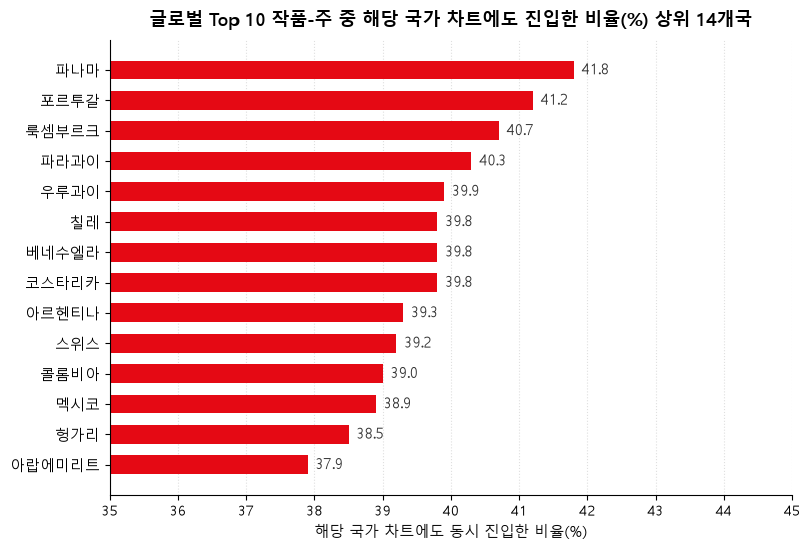

저장: C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\넷플릭스_분석_노트북\출력물\figures\11_weekly_country_coupling_v2.png
국가/값:
  파나마: 41.8
  포르투갈: 41.2
  룩셈부르크: 40.7
  파라과이: 40.3
  우루과이: 39.9
  칠레: 39.8
  베네수엘라: 39.8
  코스타리카: 39.8
  아르헨티나: 39.3
  스위스: 39.2
  콜롬비아: 39.0
  멕시코: 38.9
  헝가리: 38.5
  아랍에미리트: 37.9


In [2]:
# -*- coding: utf-8 -*-
"""그림 1 재생성: 동시진입률 상위 14개국 · x축 35~45(1단위 눈금) · 국가명 한글"""
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
d = pd.read_csv(ROOT / "data/processed/weekly_country_coupling.csv")
top = d.sort_values("동시진입률", ascending=False).head(14)

KO = {
    "Panama": "파나마", "Portugal": "포르투갈", "Luxembourg": "룩셈부르크",
    "Paraguay": "파라과이", "Uruguay": "우루과이", "Chile": "칠레",
    "Venezuela": "베네수엘라", "Costa Rica": "코스타리카", "Argentina": "아르헨티나",
    "Switzerland": "스위스", "Colombia": "콜롬비아", "Mexico": "멕시코",
    "Hungary": "헝가리", "United Arab Emirates": "아랍에미리트",
    "Singapore": "싱가포르", "Malaysia": "말레이시아", "Hungary ": "헝가리",
}
names = [KO.get(c, c) for c in top.country_name]
vals = (top["동시진입률"] * 100).round(1)

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(8.2, 5.6))
y = range(len(names))[::-1]  # 1위가 맨 위
b = ax.barh(list(y), vals, color="#e50914", height=0.62)
for yi, v in zip(y, vals):
    ax.text(v + 0.12, yi, f"{v:.1f}", va="center", fontsize=10.5, color="#333")
ax.set_yticks(list(y))
ax.set_yticklabels(names, fontsize=11)
ax.set_xlim(35, 45)
ax.set_xticks(range(35, 46, 1))
ax.set_xlabel("해당 국가 차트에도 동시 진입한 비율(%)", fontsize=11)
ax.set_title("글로벌 Top 10 작품-주 중 해당 국가 차트에도 진입한 비율(%) 상위 14개국",
             fontsize=13, fontweight="bold", pad=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", linestyle=":", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
out = NBOUT / "figures" / "11_weekly_country_coupling_v2.png"
plt.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("저장:", out)
print("국가/값:")
for n, v in zip(names, vals):
    print(f"  {n}: {v:.1f}")


**원본 코드** — `scripts/07_power_basis_check.py`

In [3]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 07. 누적 파워셰어(그림 2 기준) vs 기간별 파워(그림 3 기준) 차이 검증
#        미국: 누적 20.14% (1위) vs 2026H1 13.4% (4위) — 두 그림의 기준 차이 입증
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, numpy 2.5.4 — requirements.txt 참고
#        실행: python scripts/07_power_basis_check.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")

p = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
us = p[p.country == "United States"].iloc[0]
print("== 그림 2 기준: 전 기간(281주) 누적 추정 ==")
print(f"미국 나라파워셰어: {us['나라파워셰어']*100:.2f}%  (전체 1위)")

ry = pd.read_csv(ROOT / "data/processed/market_power_rolling_yearly.csv", index_col=0)
print("\n== 그림 3 기준: 기간별 각각 재추정 (각 시점 합계 100%) ==")
col = ry["2026H1"].sort_values(ascending=False)
for k, v in col.head(5).items():
    print(f"  {k}: {v*100:.1f}%")
print("2026H1 합계:", round(ry['2026H1'].sum()*100, 1), "%")

# 미국: 기간별 값의 기간가중 평균 vs 누적값
w = {"2021H2": 0.5, "2022": 1.0, "2023": 1.0, "2024": 1.0, "2025": 1.0, "2026H1": 0.5}
us_vals = ry.loc["미국"]
num = sum(us_vals[c] * 100 * w[c] for c in w)
den = sum(w.values())
print(f"\n미국 기간별 값: {[f'{us_vals[c]*100:.1f}' for c in w]}")
print(f"미국 기간가중 평균: {num/den:.1f}%  vs  누적 추정 20.14%")


== 그림 2 기준: 전 기간(281주) 누적 추정 ==
미국 나라파워셰어: 20.14%  (전체 1위)

== 그림 3 기준: 기간별 각각 재추정 (각 시점 합계 100%) ==
  인도: 23.7%
  브라질: 21.3%
  동아시아: 15.2%
  미국: 13.4%
  캐나다: 8.4%
2026H1 합계: 100.0 %

미국 기간별 값: ['19.7', '7.1', '18.4', '15.1', '21.8', '13.4']
미국 기간가중 평균: 15.8%  vs  누적 추정 20.14%


**원본 코드** — `scripts/12_power_charts.py`

In [4]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 12. 시장 파워 그래프 생성
#        16_power_top8.png (국가별 파워셰어 상위 8개국 막대그래프)
#        17_power_trend.png (블록별 파워셰어 연도별 추이 선그래프)
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, matplotlib 3.11.2 — requirements.txt 참고
#        (한국어 렌더링: Malgun Gothic)
#        실행: python scripts/12_power_charts.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
import matplotlib
pass  # 노트북 실행용 — Agg 비활성
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")
FIG = NBOUT_F

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RED, DARK, GRAY, LGRAY = "#e50914", "#141414", "#7a7a7a", "#c9c9c9"

# ===== 1) 국가별 시장 파워 상위 8개국 =====
names = ["미국", "인도", "브라질", "캐나다", "일본", "멕시코", "인도네시아", "대한민국"]
vals = [20.14, 18.51, 16.45, 9.13, 8.83, 7.90, 3.72, 3.69]
dens = [3.03, 0.66, 4.05, 11.86, 3.79, 3.12, 0.68, 3.76]

fig, ax = plt.subplots(figsize=(8.6, 4.3), dpi=160)
y = range(len(names))
ax.barh(y, vals, height=0.62, color=[RED] * 6 + [LGRAY] * 2, zorder=3)
ax.set_yticks(list(y))
ax.set_yticklabels(names, fontsize=11)
ax.invert_yaxis()
ax.set_xlim(0, 24)
ax.set_xlabel("글로벌 시청량 중 그 시장이 실제로 만드는 비중 (%, 파워셰어)", fontsize=9.5, color="#555")
for i, (v, d) in enumerate(zip(vals, dens)):
    ax.text(v + 0.25, i, f"{v:.1f}%", va="center", fontsize=10, fontweight="bold", color=DARK)
    ax.text(v + 2.6, i, f"밀도 {d}", va="center", fontsize=8.5, color=GRAY)
ax.grid(axis="x", color="#eee", zorder=0)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#ccc")
ax.tick_params(left=False, bottom=False)
fig.tight_layout()
fig.savefig(FIG / "16_power_top8.png", facecolor="white", bbox_inches="tight")
plt.close(fig)

# ===== 2) 시간에 따른 파워 이동 =====
periods = ["2021H2", "2022", "2023", "2024", "2025", "2026H1"]
series = {
    "미국":     ([19.7, 7.1, 18.4, 15.1, 21.8, 13.4], DARK),
    "인도":     ([12.1, 27.4, 18.6, 20.7, 19.4, 23.7], RED),
    "브라질":   ([18.8, 13.7, 13.9, 14.6, 18.6, 21.3], "#b20710"),
    "캐나다":   ([20.2, 7.3, 7.1, 8.1, 7.7, 8.4], GRAY),
    "동아시아": ([0.0, 13.8, 13.1, 20.2, 12.0, 15.2], "#ff7562"),
    "멕시코":   ([16.6, 11.2, 12.2, 8.6, 1.5, 1.4], LGRAY),
}
fig, ax = plt.subplots(figsize=(8.6, 4.5), dpi=160)
x = range(len(periods))
offsets = {"인도": 0.5, "브라질": -0.5, "동아시아": 0.7, "미국": -0.7, "캐나다": 0.3, "멕시코": -0.3}
for name, (v, c) in series.items():
    ax.plot(list(x), v, color=c, lw=2.2, marker="o", ms=4.5, zorder=3)
    ax.annotate(f"{name} {v[-1]:.1f}", (len(periods) - 1 + 0.08, v[-1] + offsets.get(name, 0)),
                fontsize=9, color=c, va="center", fontweight="bold")
ax.set_xticks(list(x))
ax.set_xticklabels(periods, fontsize=10)
ax.set_xlim(-0.3, len(periods) - 0.25)
ax.set_ylim(-1.5, 29)
ax.set_ylabel("블록별 파워셰어 (%)", fontsize=9.5, color="#555")
ax.grid(axis="y", color="#eee", zorder=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color("#ccc")
ax.spines["bottom"].set_color("#ccc")
ax.tick_params(left=False, bottom=False)
fig.tight_layout()
fig.savefig(FIG / "17_power_trend.png", facecolor="white", bbox_inches="tight")
plt.close(fig)
print("그래프 2장 생성 완료: 16_power_top8.png, 17_power_trend.png")


그래프 2장 생성 완료: 16_power_top8.png, 17_power_trend.png


**원본 코드** — `scripts/16_market_power_v3_verify.py`

In [5]:
# -*- coding: utf-8 -*-
# ─────────────────────────────────────────────────────────────────────────────
# [용도] 16. 시장 파워 v3 — 방법론 기록 + 결과 파일 내부 정합성 검증
#
# [방법론 (원 설계 기록)]
#   ① 작품 고정효과 통제: 같은 작품이 여러 나라 차트에 오르는 패턴을 이용해
#      "작품 자체의 인기 수준"을 통제한 상태에서 나라별 기여를 분리
#   ② NNLS 블록 분해: 94개국을 14개 블록(미국·캐나다·인도·브라질·동아시아 등)으로
#      묶고, 각 블록이 글로벌 시청량을 만드는 비중을 비음수 최소제곱(NNLS)으로 추정
#      — 음수를 허용하지 않으므로 "파워는 있거나 0"
#   ③ 리프트(미러) 분리: 각 나라 차트가 글로벌 차트를 따라오는 정도(리프트)를
#      따로 계산해 파워(시청량 창출)와 미러(따라잡기)를 분리
#   ④ 연도별 재추정 검증: 2021H2~2026H1을 기간별로 다시 추정해 추세 확인
#
# [주의] 원본 구현 코드는 미보존. 본 스크립트는 결과 파일의 내부 정합성을 검증하는
#        재현 코드이며, NNLS 추정 자체를 다시 수행하지는 않는다.
# [환경] Python 3.15.2 (Windows) / pandas 3.1.1, numpy 2.5.4 — requirements.txt 참고
#        실행: python scripts/16_market_power_v3_verify.py
# [경로] ROOT = 스크립트 위치 기준 프로젝트 루트 (scripts/ 상위)
# ─────────────────────────────────────────────────────────────────────────────
import pandas as pd
from pathlib import Path

ROOT = Path(r"C:\Users\USER\Desktop\엘리스 개인 프로젝트 자료\[엔터] Netflix Top 10 Weekly Dataset")

# ---- 1) 국가별 파워 (country_market_power.csv) ----
p = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
print("== country_market_power.csv ==")
print(f"행 수(국가): {len(p)} | 컬럼: {list(p.columns)[:8]}...")
total_share = p.나라파워셰어.sum()
print(f"나라파워셰어 합계: {total_share:.4f} (1.0 = 글로벌 시청량 100%)")
print(f"상위 5개국: {p.nlargest(5, '나라파워셰어')[['country', '나라파워셰어']].to_string(index=False)}")

# ---- 2) 밀도 열 정합성 (파워/인구비 연도별 존재 확인) ----
dens_cols = [c for c in p.columns if "파워/인구비" in c]
print(f"\n밀도 열 (파워/인구비): {dens_cols}")

# ---- 3) 사분면 분포 (파워 × 미러 분류 결과) ----
if "사분면" in p.columns:
    print(f"\n사분면 분포: {p.사분면.value_counts().to_dict()}")

# ---- 4) 연도별 롤링 추정 (market_power_rolling_yearly.csv) ----
ry = pd.read_csv(ROOT / "data/processed/market_power_rolling_yearly.csv", index_col=0)
print("\n== market_power_rolling_yearly.csv ==")
print(f"블록 {len(ry)}개 × 기간 {len(ry.columns)}개")
for c in ry.columns:
    s = ry[c].sum()
    flag = "OK" if abs(s - 1.0) < 0.01 else "확인 필요"
    print(f"  {c}: 합계 {s*100:.1f}% [{flag}] — 각 시점 합계 100% 검증")

# ---- 5) 14개 블록 정의 (market_power_blocks_v3.csv) ----
blocks = pd.read_csv(ROOT / "data/processed/market_power_blocks_v3.csv")
print(f"\n== market_power_blocks_v3.csv (블록 정의) ==")
print(f"행 수: {len(blocks)} | 컬럼: {list(blocks.columns)}")

# ---- 6) 순수 미러 시장 (파워 ≈ 0 & 리프트 높음) ----
mirror = p[(p.나라파워셰어 < 0.001) & (p["리프트(미러)"] >= 3.9)]
print(f"\n순수 미러 시장 (파워<0.1% & 리프트≥3.9): {len(mirror)}개국")
print(mirror[["country", "리프트(미러)"]].head(8).to_string(index=False))


== country_market_power.csv ==
행 수(국가): 94 | 컬럼: ['country', '블록', '나라파워셰어', '리프트(미러)', '인구2024', '대륙', '사분면', '인구_2021_2025합']...
나라파워셰어 합계: 1.0000 (1.0 = 글로벌 시청량 100%)
상위 5개국:       country  나라파워셰어
United States 0.20140
        India 0.18510
       Brazil 0.16450
       Canada 0.09130
        Japan 0.08833

밀도 열 (파워/인구비): ['참고_파워/인구비_5년누적(구)', '참고_파워/인구비_2024단년(구)', '파워/인구비_2021', '파워/인구비_2022', '파워/인구비_2023', '파워/인구비_2024', '파워/인구비_2025', '파워/인구비_2026']

사분면 분포: {'순수미러': 41, '저활성': 38, '파워형(독립시장)': 13, '파워+미러': 2}

== market_power_rolling_yearly.csv ==
블록 14개 × 기간 6개
  2021H2: 합계 100.0% [OK] — 각 시점 합계 100% 검증
  2022: 합계 100.0% [OK] — 각 시점 합계 100% 검증
  2023: 합계 100.0% [OK] — 각 시점 합계 100% 검증
  2024: 합계 100.0% [OK] — 각 시점 합계 100% 검증
  2025: 합계 100.0% [OK] — 각 시점 합계 100% 검증
  2026H1: 합계 100.0% [OK] — 각 시점 합계 100% 검증

== market_power_blocks_v3.csv (블록 정의) ==
행 수: 14 | 컬럼: ['블록', '파워셰어', '인구셰어', '파워/인구비']

순수 미러 시장 (파워<0.1% & 리프트≥3.9): 49개국
            country  리프트(미러)
          Guatemala

### 보고서 수치 산출 — 순수 미러 41개국·시장 밀도(캐나다 11.9 vs 인도 0.66)

미러 분리 박스의 "순수 미러 시장 41개국"과 그림 2 캡션의 파워/인구 밀도 수치를 결과 파일에서 산출한다.
(NNLS 추정 본체는 미보존 — 방법론은 scripts/16 마크다운 기록 + 본 검증으로 근거를 대신한다)

In [6]:
mp = pd.read_csv(ROOT / "data/processed/country_market_power.csv")
q = mp["사분면"].value_counts()
print("== 사분면별 국가 수 ==")
print(q.to_string())
mirror = mp[mp["사분면"] == "순수미러"].sort_values("리프트(미러)", ascending=False)
print(f"\n순수 미러 시장 {len(mirror)}개국 — 리프트 상위 10:")
print(mirror[["country", "리프트(미러)"]].head(10).to_string(index=False))
dens = mp.set_index("country")["파워/인구비_2024"]
print(f"\n파워/인구 밀도 — 캐나다 {dens['Canada']:.1f} vs 인도 {dens['India']:.2f} vs 호주 {dens['Australia']:.1f}")
print("파워 상위 8개국(그림 2 기준):")
print(mp.sort_values("나라파워셰어", ascending=False)[["country", "나라파워셰어"]].head(8).to_string(index=False))

== 사분면별 국가 수 ==
사분면
순수미러         41
저활성          38
파워형(독립시장)    13
파워+미러         2

순수 미러 시장 41개국 — 리프트 상위 10:
   country  리프트(미러)
    Panama     5.31
 Venezuela     4.96
     Chile     4.94
  Paraguay     4.93
Costa Rica     4.92
  Portugal     4.91
  Colombia     4.91
   Uruguay     4.88
Luxembourg     4.87
 Argentina     4.77

파워/인구 밀도 — 캐나다 11.9 vs 인도 0.66 vs 호주 5.8
파워 상위 8개국(그림 2 기준):
      country  나라파워셰어
United States 0.20140
        India 0.18510
       Brazil 0.16450
       Canada 0.09130
        Japan 0.08833
       Mexico 0.07900
    Indonesia 0.03716
  South Korea 0.03691


### 모델 B 취향 지도 — 세 개 취향 그룹 시각화

94×94 취향 유사도 행렬을 계층적 군집화로 3개 그룹으로 나눠, 국가 이름 없이 그룹 색만으로 묶임을 보여준다.

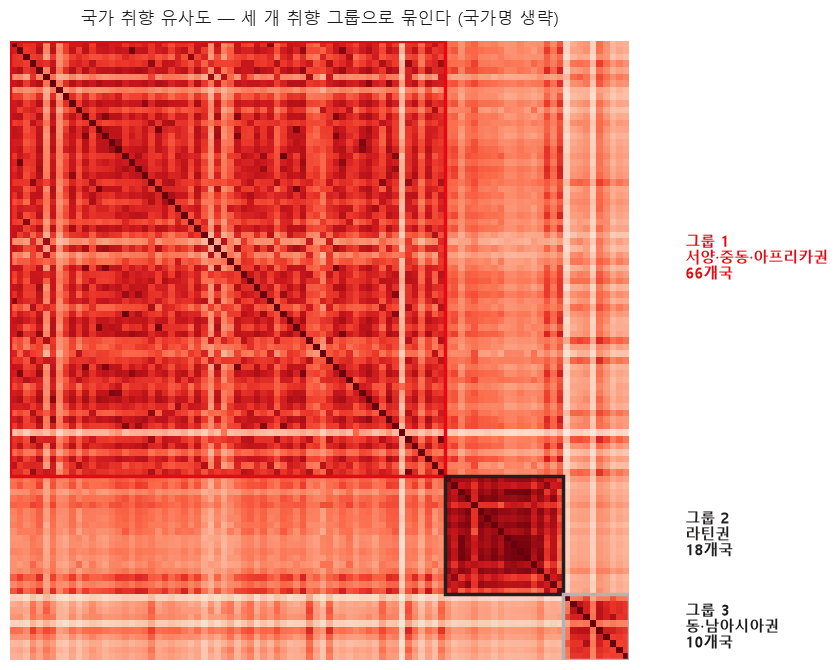

그룹 1 (서양·중동·아프리카권) — 66개국 | 예: Australia, Austria, Bahamas, Bahrain, Belgium, Bangladesh
그룹 2 (라틴권) — 18개국 | 예: Chile, Argentina, Nicaragua, Panama, Mexico, Paraguay
그룹 3 (동·남아시아권) — 10개국 | 예: Japan, Indonesia, Malaysia, Hong Kong, South Korea, Singapore


In [7]:
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

sim = pd.read_csv(ROOT / "data/processed/country_taste_similarity.csv", index_col=0)
cont = pd.read_csv(ROOT / "references/country_continent.csv")
CONT = dict(zip(cont.country_name, cont["대륙"]))

# 계층적 군집화(ward 연결)로 3개 그룹
dist = 1 - sim.to_numpy(float)
np.fill_diagonal(dist, 0)
dist = (dist + dist.T) / 2
Z = linkage(squareform(dist, checks=False), method="ward")
labels = fcluster(Z, t=3, criterion="maxclust")
order = np.argsort(labels)
names = sim.index.to_numpy()[order]
labels_sorted = labels[order]
mat = sim.to_numpy(float)[np.ix_(order, order)]

# 그룹 이름: 구성 기반 (남미+중미 우세=라틴권, 동·남아시아 국가 명단 우세=동·남아시아권, 그 외=서양·중동·아프리카권)
EA = {"Japan", "South Korea", "Taiwan", "Hong Kong", "Singapore", "Malaysia",
      "Indonesia", "Thailand", "Vietnam", "Philippines", "Cambodia", "Myanmar"}
grp_names = {}
for lab in [1, 2, 3]:
    idx = np.where(labels_sorted == lab)[0]
    members = [n for n in names[idx]]
    regions = [CONT.get(n, "?") for n in members]
    vc = pd.Series(regions).value_counts()
    lat = vc.get("남미", 0) + vc.get("중미·카리브", 0)
    ea = sum(1 for n in members if n in EA)
    if lat >= 8:
        grp_names[lab] = "라틴권"
    elif ea >= 8:
        grp_names[lab] = "동·남아시아권"
    else:
        grp_names[lab] = "서양·중동·아프리카권"

import matplotlib.pyplot as plt
GROUP_COLORS = ["#e50914", "#221f1f", "#b3b3b3"]
fig, ax = plt.subplots(figsize=(8.6, 6.8))
im = ax.imshow(mat, cmap="Reds", vmin=0, vmax=1)
for lab in [1, 2, 3]:
    idx = np.where(labels_sorted == lab)[0]
    ax.add_patch(plt.Rectangle((idx[0] - 0.5, idx[0] - 0.5), len(idx), len(idx),
                               fill=False, edgecolor=GROUP_COLORS[lab - 1], lw=2.5))
    ax.text(len(mat) + 8, (idx[0] + idx[-1]) / 2,
            f"그룹 {lab}\n{grp_names[lab]}\n{len(idx)}개국", fontsize=10.5, va="center",
            color=GROUP_COLORS[lab - 1] if GROUP_COLORS[lab - 1] != "#b3b3b3" else "#1a1a1a",
            fontweight="bold")
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("국가 취향 유사도 — 세 개 취향 그룹으로 묶인다 (국가명 생략)",
             fontsize=12.5, color="#1a1a1a", pad=12)
for s in ax.spines.values():
    s.set_visible(False)
plt.tight_layout(); plt.savefig(NBOUT_F / "eda_taste_clusters.png", dpi=150); plt.show()

for lab in [1, 2, 3]:
    idx = np.where(labels_sorted == lab)[0]
    sample = [n for n in names[idx]][:6]
    print(f"그룹 {lab} ({grp_names[lab]}) — {len(idx)}개국 | 예: {', '.join(sample)}")